In [9]:
import pandas as pd

In [10]:
import numpy as np


In [11]:
import matplotlib.pyplot as plt

In [12]:
import seaborn as sns


In [13]:
# Load your uploaded file with its exact name
df = pd.read_excel('BlinkIT Grocery Data (1).xlsx')
print("Dataset Loaded Successfully! Shape:", df.shape)

Dataset Loaded Successfully! Shape: (3, 2)


In [14]:
# Check missing values (Objective 2.1)
print("\n--- Missing Values Check ---")
print(df.isnull().sum())


--- Missing Values Check ---
Unnamed: 0    3
Unnamed: 1    2
dtype: int64


In [15]:
# Explicitly load the correct sheet name from your Excel file
df = pd.read_excel('BlinkIT Grocery Data (1).xlsx', sheet_name='BlinkIT Grocery Data')


In [16]:
print("Fixed! Dataset Shape:", df.shape)
print("\n--- First 3 Rows ---")
display(df.head(3))


Fixed! Dataset Shape: (8523, 12)

--- First 3 Rows ---


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0


In [17]:
# Check missing values (Objective 2.1)
print("\n--- Missing Values Check ---")
print(df.isnull().sum())


--- Missing Values Check ---
Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64


In [18]:
# Objective 1: Calculate Core Business Metrics
total_sales = df['Sales'].sum()
avg_sales = df['Sales'].mean()
total_items = df['Sales'].count()
avg_rating = df['Rating'].mean()


In [19]:
print("========================================")
print("     BLINKIT OVERVIEW METRICS           ")
print("========================================")
print(f"Total Sales        : ₹{total_sales:,.2f}")
print(f"Average Sale Value : ₹{avg_sales:,.2f}")
print(f"Total Items Sold   : {total_items:,}")
print(f"Average Rating     : {avg_rating:.2f} / 5.0")
print("========================================")

     BLINKIT OVERVIEW METRICS           
Total Sales        : ₹1,201,681.49
Average Sale Value : ₹140.99
Total Items Sold   : 8,523
Average Rating     : 3.97 / 5.0


In [20]:
# Clean and standardize Item Fat Content (Objective 2.4)
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})


<Figure size 1200x600 with 0 Axes>

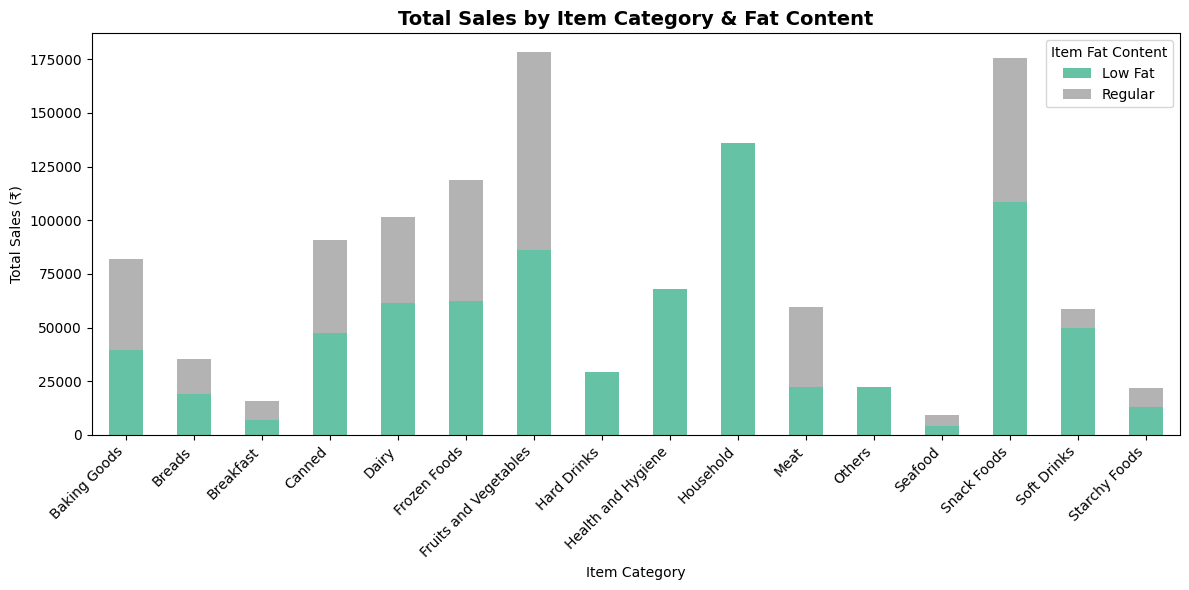

In [21]:
# Chart 1: Total Sales by Item Category & Fat Content
plt.figure(figsize=(12, 6))
sales_by_cat_fat = df.groupby(['Item Type', 'Item Fat Content'])['Sales'].sum().unstack()
sales_by_cat_fat.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='Set2')
plt.title('Total Sales by Item Category & Fat Content', fontsize=14, fontweight='bold')
plt.ylabel('Total Sales (₹)')
plt.xlabel('Item Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

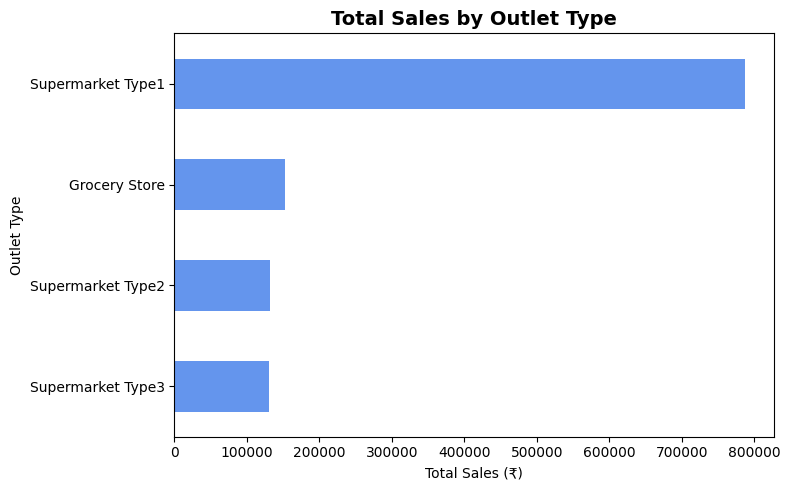

In [22]:
# Chart 2: Sales by Outlet Type
plt.figure(figsize=(8, 5))
sales_by_outlet = df.groupby('Outlet Type')['Sales'].sum().sort_values()
sales_by_outlet.plot(kind='barh', color='cornflowerblue')
plt.title('Total Sales by Outlet Type', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales (₹)')
plt.ylabel('Outlet Type')
plt.tight_layout()
plt.show()